Training finished!
Average reward (last 1000 episodes): 7.29
Successful drop-offs during training: 19758


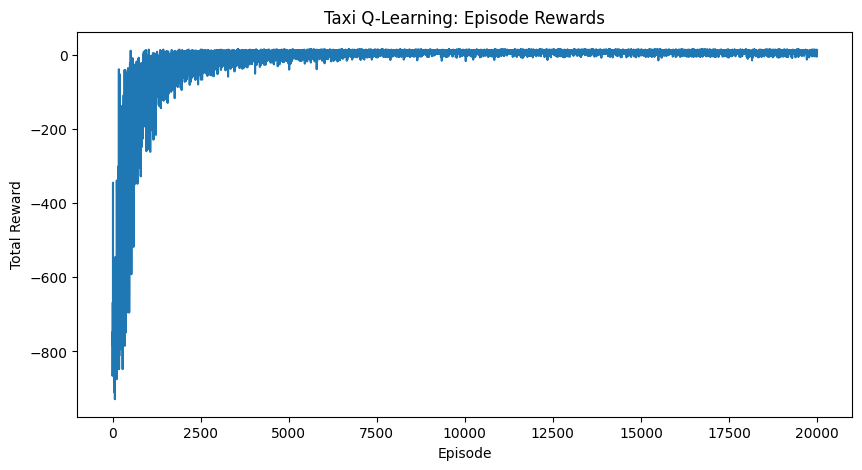

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)

Episode 1: Steps = 14, Reward = 7
----------------------------------------
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)

Episode 2: Steps = 10, Reward = 11
----------------------------------------
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)

Episode 3: Steps = 15, Reward = 6
----------------------------------------
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)

Episode 4: Steps = 12, Reward = 9
----------------------------------------
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)

Episode 5: Steps = 15, Reward = 6
----------------------------------------


In [1]:

import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

# Step 1: Initialize the environment
env = gym.make("Taxi-v4")

n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

# Step 2: Set hyperparameters
alpha = 0.8
gamma = 0.95
epsilon = 1.0
min_epsilon = 0.01
decay = 0.9995
episodes = 20000
max_steps = 200

rewards = []
success_count = 0

# Step 3: Train the agent using Q-learning
for ep in range(episodes):
    state, info = env.reset()
    total_reward = 0

    for step in range(max_steps):

        # Epsilon-greedy action selection
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = int(np.argmax(Q[state]))

        # Perform action
        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        # Update Q-table
        Q[state, action] += alpha * (
            reward + gamma * np.max(Q[next_state]) * (not terminated)
            - Q[state, action]
        )

        state = next_state
        total_reward += reward

        if done:
            if terminated and reward == 20:
                success_count += 1
            break

    rewards.append(total_reward)

    # Reduce exploration
    epsilon = max(min_epsilon, epsilon * decay)

# Step 4: Display training results
print("Training finished!")
print("Average reward (last 1000 episodes):",
      round(np.mean(rewards[-1000:]), 2))
print("Successful drop-offs during training:", success_count)

# Step 5: Plot rewards
plt.figure(figsize=(10, 5))
plt.plot(rewards)
plt.title("Taxi Q-Learning: Episode Rewards")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.show()

# Step 6: Test the trained agent
eval_env = gym.make("Taxi-v4", render_mode="ansi")

for ep in range(5):
    state, info = eval_env.reset()
    total_reward = 0

    for step in range(max_steps):
        action = int(np.argmax(Q[state]))

        state, reward, terminated, truncated, info = eval_env.step(action)
        total_reward += reward

        if terminated or truncated:
            break

    print(eval_env.render())
    print(f"Episode {ep + 1}: Steps = {step + 1}, Reward = {total_reward}")
    print("-" * 40)

env.close()
eval_env.close()
